<a href="https://colab.research.google.com/github/GerardoMunoz/Vision/blob/main/Autoencoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train.reshape((-1, 784))
x_test = x_test.reshape((-1, 784))
print("Entrenamiento:", x_train.shape, "Prueba:", x_test.shape)

TensorFlow: 2.21.0
Entrenamiento: (60000, 784) Prueba: (10000, 784)


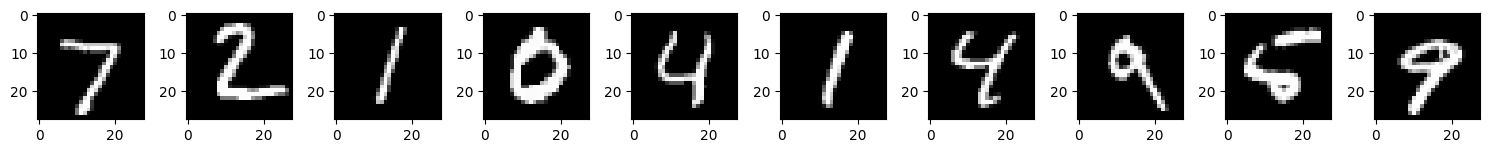

In [2]:
n = 10
fig, axes = plt.subplots(1, n, figsize=(15, 3))
for i in range(n):
    axes[ i].imshow(x_test[i].reshape(28, 28), cmap="gray")
plt.tight_layout(); plt.show()

In [3]:
latent_dim = 32

encoder = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(latent_dim, activation="relu", name="latent_vector")
], name="encoder")

decoder = keras.Sequential([
    layers.Input(shape=(latent_dim,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(784, activation="sigmoid")
], name="decoder")

autoencoder = keras.Sequential([encoder, decoder], name="autoencoder")
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")


In [4]:
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,360 (411.56 KB)

 Trainable params: 105,360 (411.56 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
autoencoder.summary(expand_nested=True)

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Sequential)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense (Dense)              │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ latent_vector (Dense)      │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Sequential)            │ (None, 784)            │       105,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense_1 (Dense)            │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense_2 (Dense)            │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

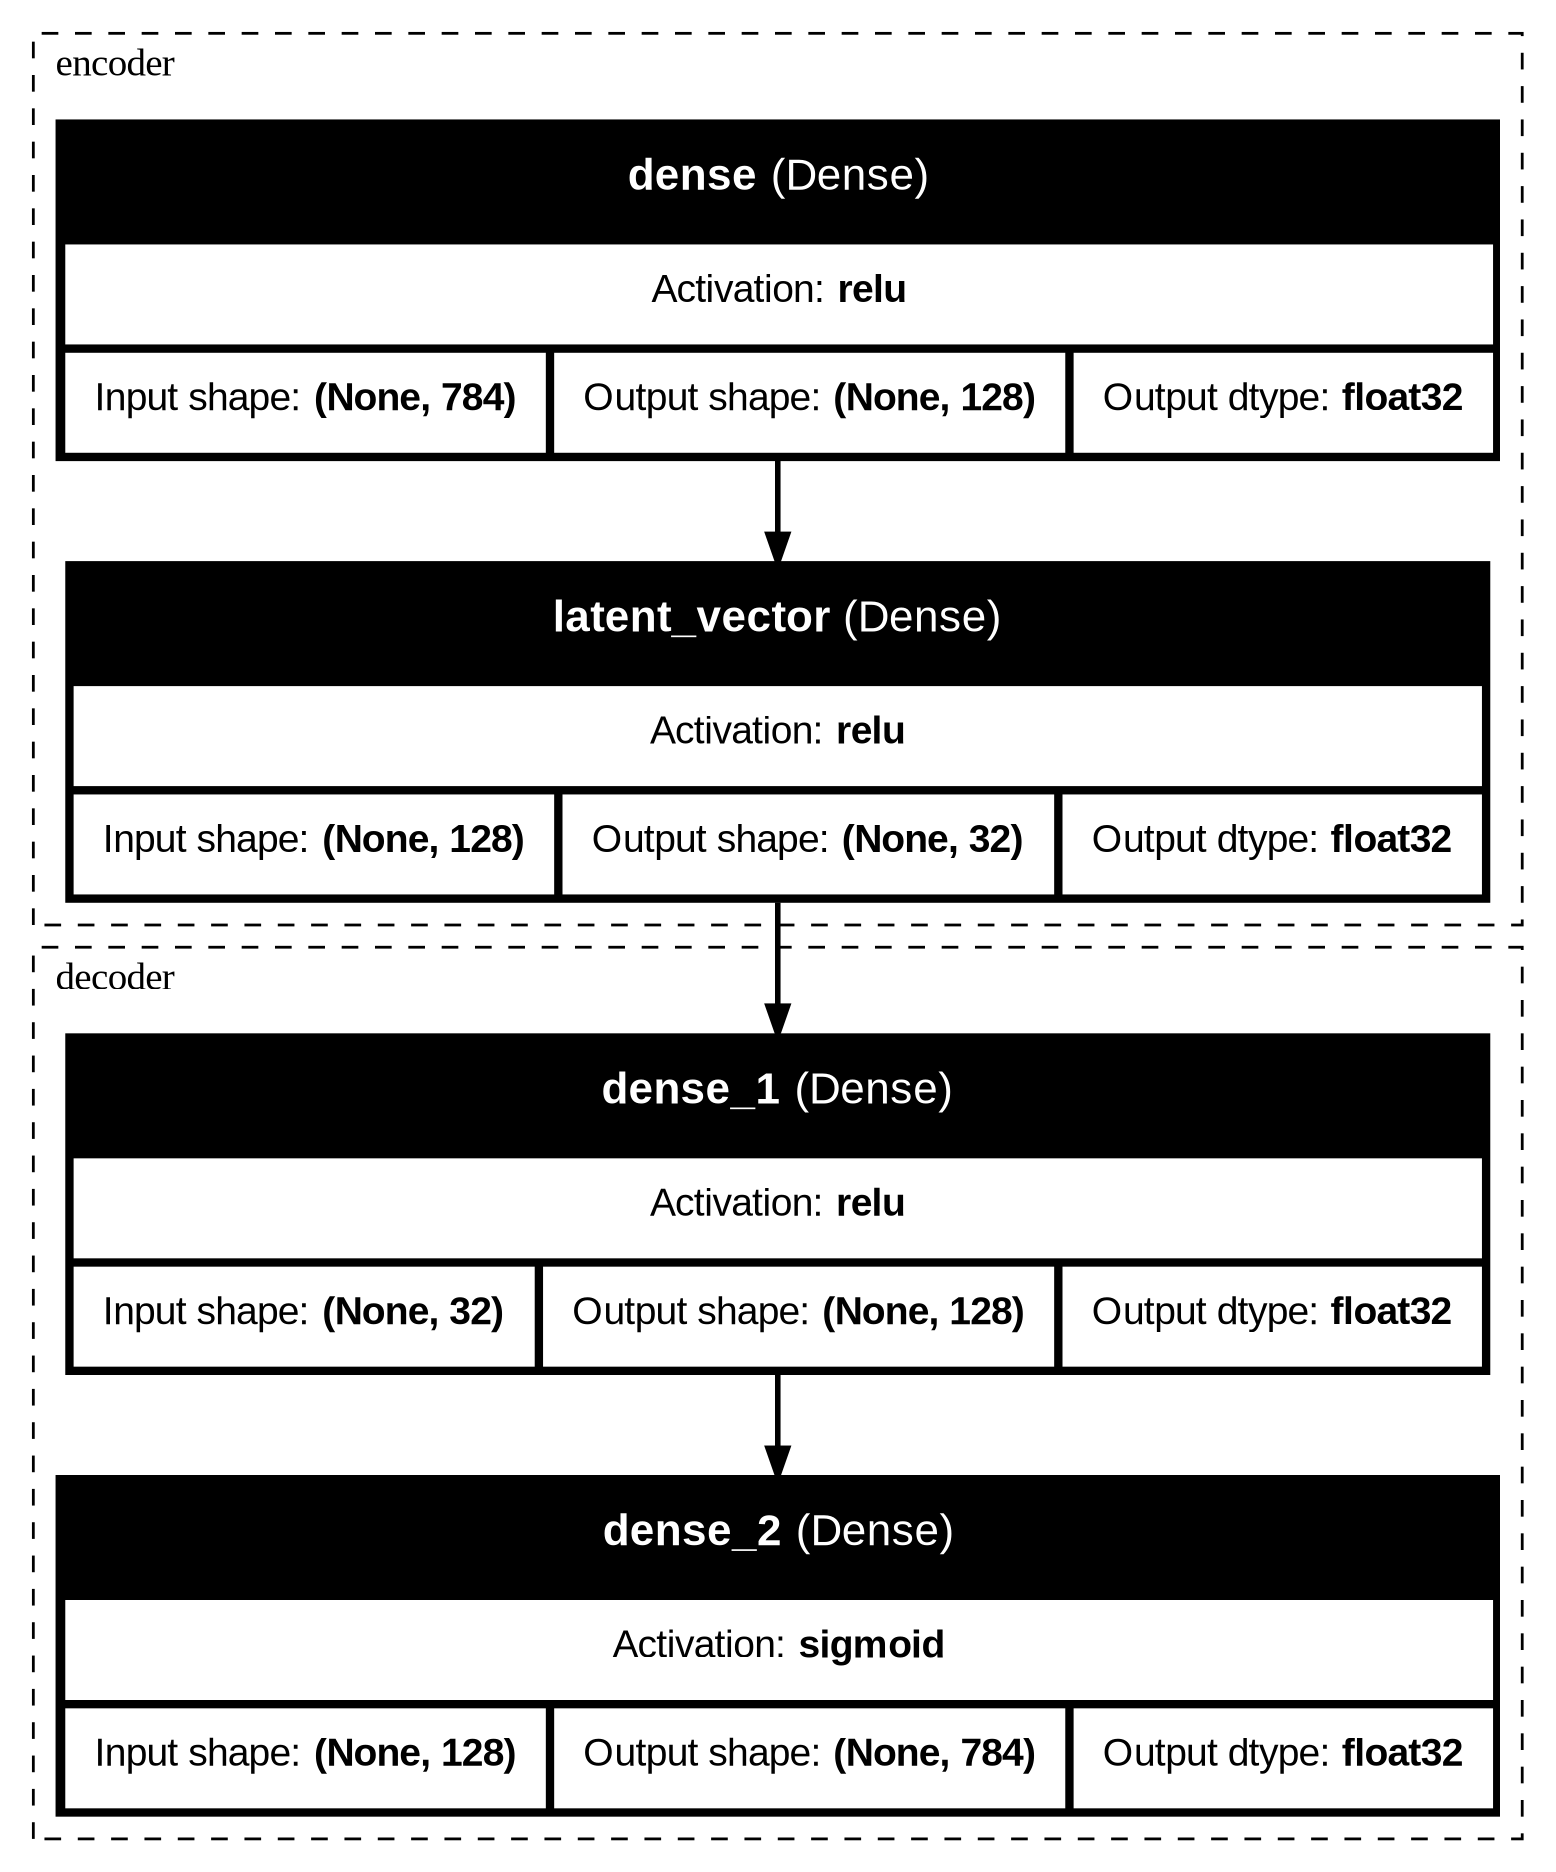

In [7]:
from tensorflow.keras.utils import plot_model

plot_model(
    autoencoder,
    show_shapes=True,
    show_layer_names=True,
    show_dtype=True,
    show_layer_activations=True,
    expand_nested=True,
    to_file='architecture.png'
)

In [8]:
loss_history = []
val_loss_history = []

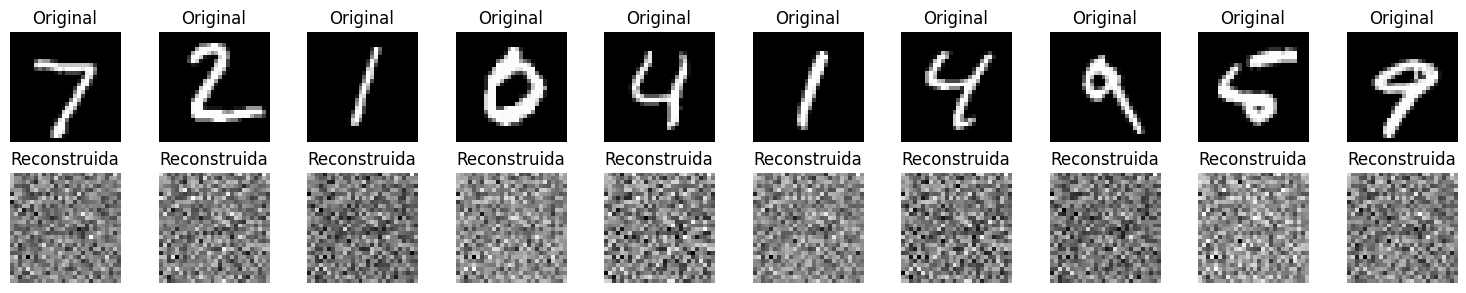

In [9]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [10]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - loss: 0.2353 - val_loss: 0.1559


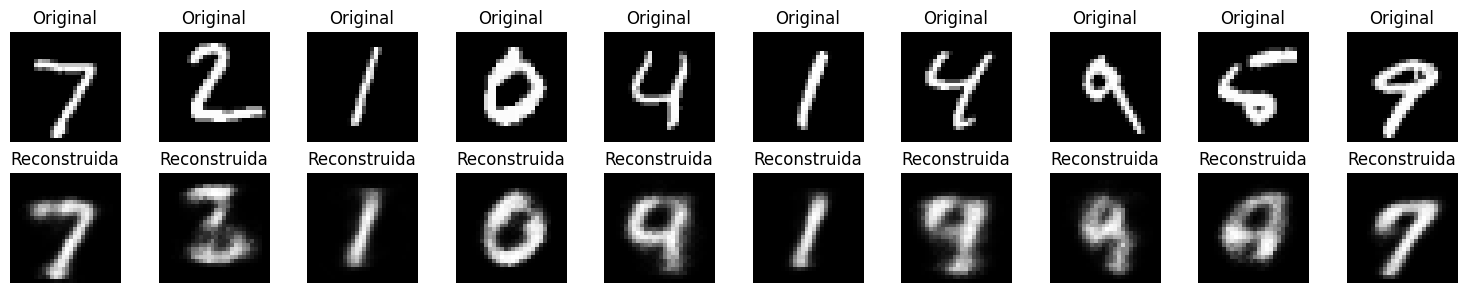

In [11]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [12]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 14s 60ms/step - loss: 0.1379 - val_loss: 0.1254


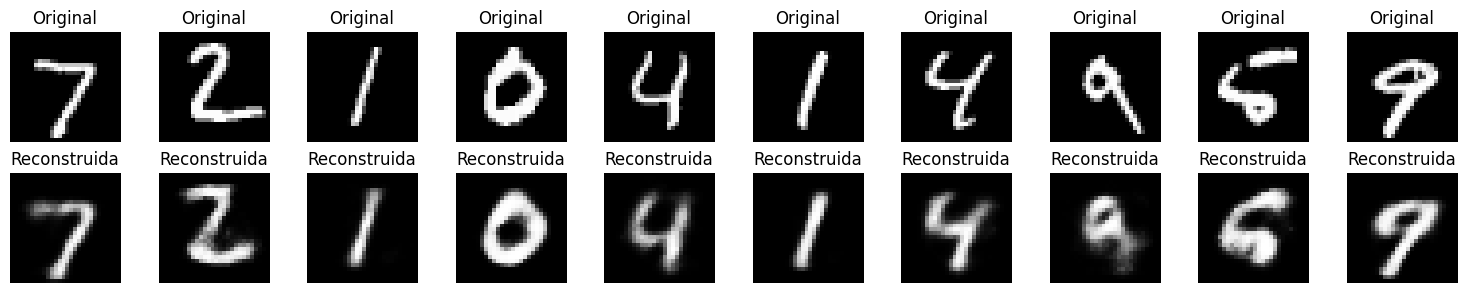

In [13]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [14]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - loss: 0.1196 - val_loss: 0.1125


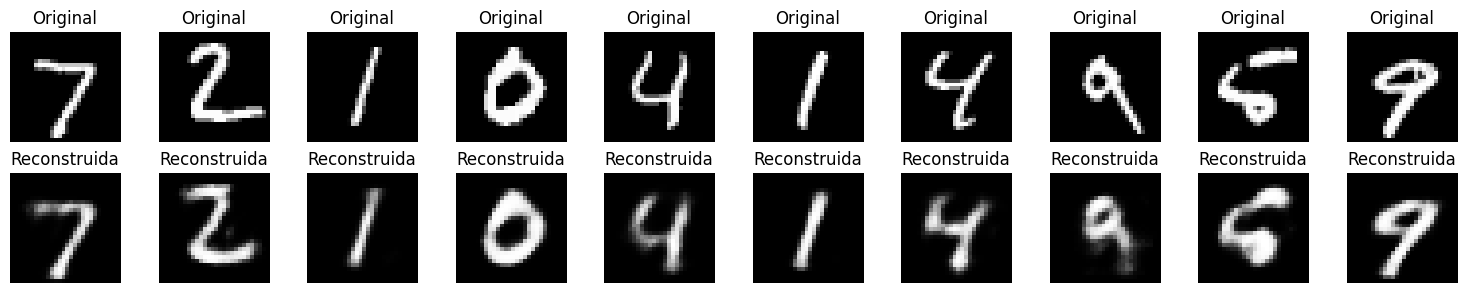

In [15]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [16]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1102 - val_loss: 0.1058


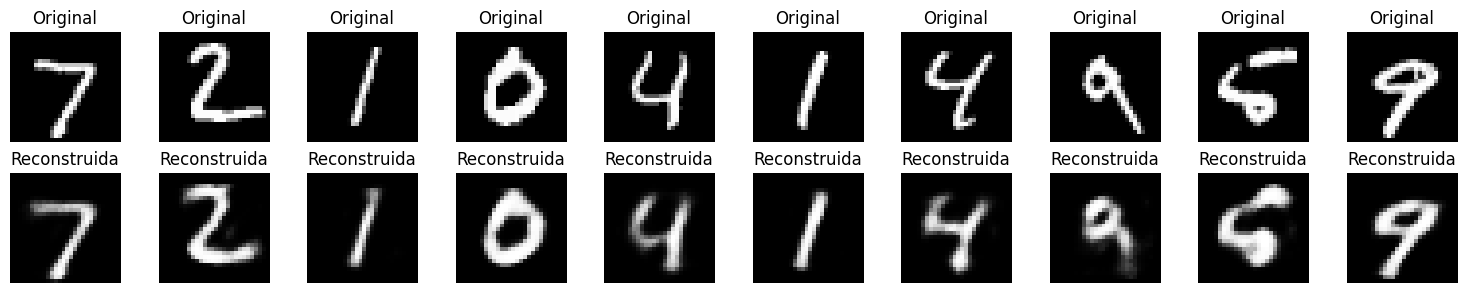

In [17]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [18]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1052 - val_loss: 0.1018


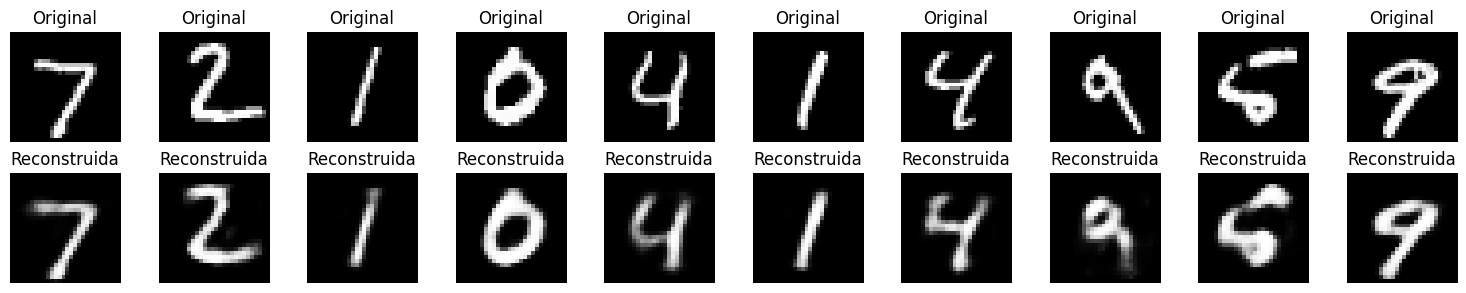

In [19]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [20]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.1020 - val_loss: 0.0995


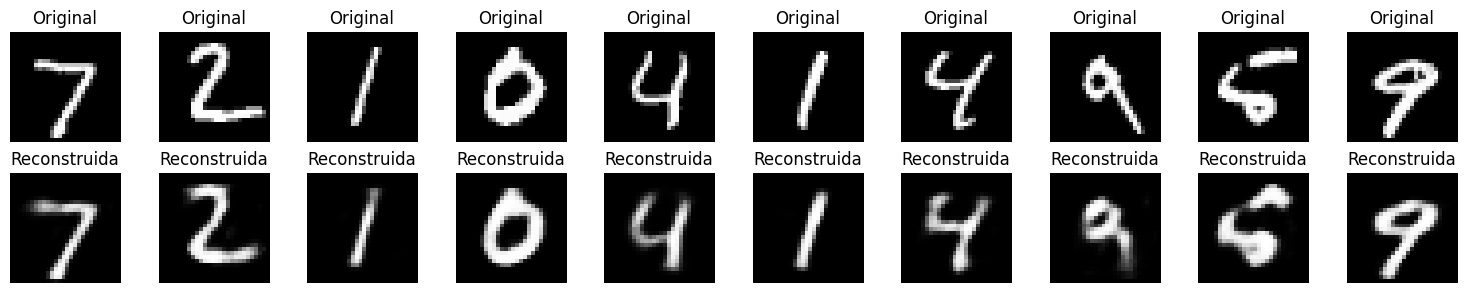

In [21]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

233/235 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.1002

In [ ]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

In [ ]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

In [ ]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

In [ ]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

In [ ]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history, label="Entrenamiento")
plt.plot(val_loss_history, label="Validación")
plt.xlabel("Época"); plt.ylabel("Binary cross-entropy")
plt.title("Pérdida del autoencoder"); plt.legend(); plt.grid(True)
plt.show()

In [ ]:
idx = 0
original = x_test[idx].reshape(28, 28)
reconstructed = reconstructions[idx].reshape(28, 28)
error_map = np.abs(original - reconstructed)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(original, cmap="gray"); axes[0].set_title("Original")
axes[1].imshow(reconstructed, cmap="gray"); axes[1].set_title("Reconstruida")
im = axes[2].imshow(error_map, cmap="magma"); axes[2].set_title("Error absoluto")
for ax in axes: ax.axis("off")
fig.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()
pred = autoencoder.predict(x_test, verbose=0)
mse = np.mean((x_test - pred)**2, axis=1)
print(f"MSE promedio en test: {mse.mean():.6f}")

In [ ]:
z = encoder.predict(x_test[:2000], verbose=0)
plt.figure(figsize=(6, 5))
plt.scatter(z[:, 0], z[:, 1], c=y_test[:2000], cmap="tab10", s=8, alpha=0.7)
plt.colorbar(label="Clase (dígito)")
plt.xlabel("Dimensión latente 1"); plt.ylabel("Dimensión latente 2")
plt.title("Dos coordenadas del espacio latente")
plt.show()

In [ ]:
from sklearn.decomposition import PCA

z = encoder.predict(x_test[:2000], verbose=0)

pca = PCA(n_components=2)
z_2d = pca.fit_transform(z)

plt.figure(figsize=(8, 6))

plt.scatter(
    z_2d[:, 0],
    z_2d[:, 1],
    c=y_test[:2000],
    cmap="tab10",
    s=8,
    alpha=0.7
)

plt.colorbar(label="Dígito")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Latent Space - PCA Visualization")
plt.show()

print("Varianza explicada:", pca.explained_variance_ratio_.sum())